# Logistic Regression

In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay,confusion_matrix,classification_report
from sklearn.preprocessing import StandardScaler

In [6]:
df = pd.read_csv("diabetes (1).csv")
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [17]:
X = df.drop("Outcome",axis=1)
y = df["Outcome"]

In [18]:
X

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,6,148,72,35,0,33.6,0.627,50
1,1,85,66,29,0,26.6,0.351,31
2,8,183,64,0,0,23.3,0.672,32
3,1,89,66,23,94,28.1,0.167,21
4,0,137,40,35,168,43.1,2.288,33
...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63
764,2,122,70,27,0,36.8,0.340,27
765,5,121,72,23,112,26.2,0.245,30
766,1,126,60,0,0,30.1,0.349,47


In [19]:
y

0      1
1      0
2      1
3      0
4      1
      ..
763    0
764    0
765    0
766    1
767    0
Name: Outcome, Length: 768, dtype: int64

In [20]:
# Train Test Split
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42, stratify=y)

In [21]:
# Standardize Insulin (fit on train, transform both)
scaler = StandardScaler()
X_train["Insulin"] = scaler.fit_transform(X_train[["Insulin"]])
X_test["Insulin"] = scaler.transform(X_test[["Insulin"]])

In [23]:
# Train Full model all features]

model = LogisticRegression(max_iter=500)
model.fit(X_train, y_train)

LogisticRegression(max_iter=500)

In [24]:
#Evaluate on Test set
y_pred = model.predict(X_test)

Text(0.5, 1.0, 'Confusion Matrix (test set)')

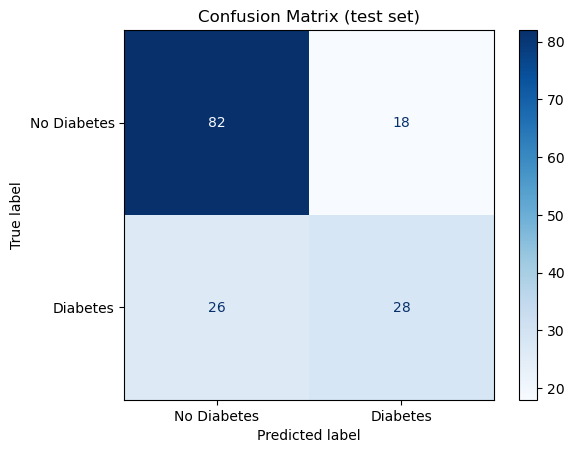

In [28]:
cm = confusion_matrix(y_test,y_pred)
ConfusionMatrixDisplay(cm,display_labels=["No Diabetes","Diabetes"]).plot(cmap="Blues")
plt.title("Confusion Matrix (test set)")

In [30]:
# 6 Logistic regression curve
# Extract Glucose from train.test split
X_train_glucose = X_train[["Glucose"]].copy()
X_test_glucose = X_test[["Glucose"]].copy()

In [31]:
# Train a separate single feature for visualization

model_glucose = LogisticRegression()
model_glucose.fit(X_train_glucose,y_train)

LogisticRegression()

In [32]:
# Create smooth curve

In [34]:
glucose_min = df["Glucose"].min()
glucose_max = df["Glucose"].max()
glucose_values = np.linspace(glucose_min,glucose_max,200).reshape(-1,1)
y_curve = model_glucose.predict_proba(glucose_values)[:,1]

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


In [35]:
plt.figure(figsize=(10,6))
plt.plot(glucose_values,y_curve,color="red",linewidth=2,label="Logistic Data")
plt.scatter(X_train_glucose, y_train, color = "green", alpha = 0.4, label - "Training data")

SyntaxError: positional argument follows keyword argument (2918974791.py, line 3)